<a href="https://colab.research.google.com/github/Sakshi-coder1/workco/blob/main/Day%204%7C%20Data%20Cleaning%20Mastery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv("titanic.csv")
print(df.shape)

(891, 15)


In [ ]:
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [ ]:
# Text Cleaning
df['embark_town']=(df["embark_town"].astype("string").str.strip().str.title())

In [ ]:
df['deck']=(df["deck"].astype("string").str.strip().str.upper())

In [ ]:
# Datatypes
print(df.dtypes)

survived                int64
pclass                  int64
sex                    object
age                   float64
sibsp                   int64
parch                   int64
fare                  float64
embarked               object
class                  object
who                    object
adult_male               bool
deck           string[python]
embark_town    string[python]
alive                  object
alone                    bool
dtype: object


In [ ]:
df["age"]=pd.to_numeric(df["age"],errors="coerce")

In [ ]:
df["fare"]=pd.to_numeric(df["fare"],errors="coerce")

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64


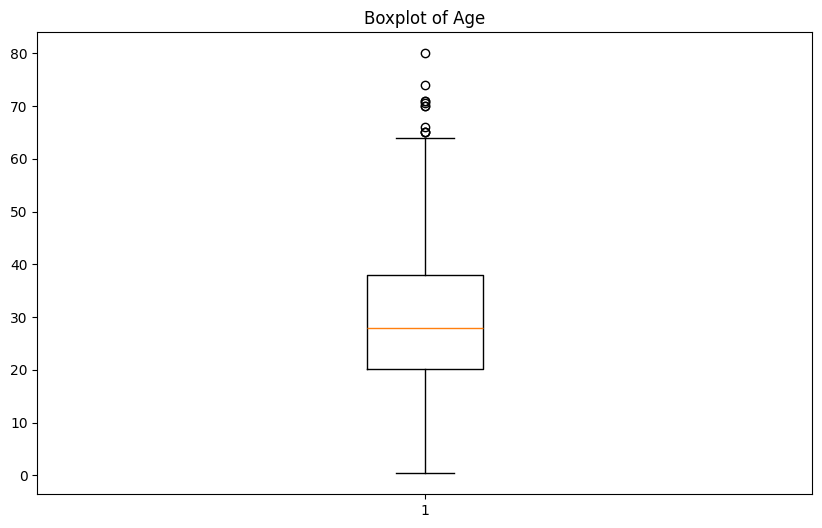

In [ ]:
# Outliers
print(df['age'].describe())
plt.figure(figsize=(10,6))
plt.boxplot(df['age'].dropna())
plt.title("Boxplot of Age")
plt.show()

In [ ]:
# IQR
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

17.875


In [ ]:
lower=Q1-1.5* IQR
upper=Q3+1.5* IQR
print(lower)
print(upper)

-6.6875
64.8125


In [ ]:
# display outliers
outliers=df[(df['age']<lower) | (df['age']>upper)]
print(outliers)

     survived  pclass   sex   age  sibsp  parch     fare embarked   class  \
33          0       2  male  66.0      0      0  10.5000        S  Second   
54          0       1  male  65.0      0      1  61.9792        C   First   
96          0       1  male  71.0      0      0  34.6542        C   First   
116         0       3  male  70.5      0      0   7.7500        Q   Third   
280         0       3  male  65.0      0      0   7.7500        Q   Third   
456         0       1  male  65.0      0      0  26.5500        S   First   
493         0       1  male  71.0      0      0  49.5042        C   First   
630         1       1  male  80.0      0      0  30.0000        S   First   
672         0       2  male  70.0      0      0  10.5000        S  Second   
745         0       1  male  70.0      1      1  71.0000        S   First   
851         0       3  male  74.0      0      0   7.7750        S   Third   

     who  adult_male  deck  embark_town alive  alone  
33   man        True

In [ ]:
# capping
df["age_original"]=df["age"]
df["age"]=df["age"].clip(lower,upper)
print(df[["age_original","age"]].head(35))

    age_original      age
0           22.0  22.0000
1           38.0  38.0000
2           26.0  26.0000
3           35.0  35.0000
4           35.0  35.0000
5            NaN      NaN
6           54.0  54.0000
7            2.0   2.0000
8           27.0  27.0000
9           14.0  14.0000
10           4.0   4.0000
11          58.0  58.0000
12          20.0  20.0000
13          39.0  39.0000
14          14.0  14.0000
15          55.0  55.0000
16           2.0   2.0000
17           NaN      NaN
18          31.0  31.0000
19           NaN      NaN
20          35.0  35.0000
21          34.0  34.0000
22          15.0  15.0000
23          28.0  28.0000
24           8.0   8.0000
25          38.0  38.0000
26           NaN      NaN
27          19.0  19.0000
28           NaN      NaN
29           NaN      NaN
30          40.0  40.0000
31           NaN      NaN
32           NaN      NaN
33          66.0  64.8125
34          28.0  28.0000


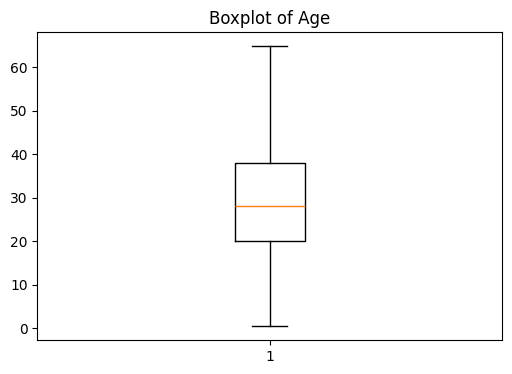

In [ ]:
plt.figure(figsize=(6,4))
plt.boxplot(df["age"].dropna())
plt.title("Boxplot of Age")
plt.show()


In [ ]:
# Combining the datasets
df1=pd.DataFrame({"Name":["Aman","Riya","Rahul"], "Age":[25,22,26]})

In [ ]:
df2=pd.DataFrame({"Name":["Kabir","Neha"], "Age":[23,24]})

In [ ]:
print(df1)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26


In [ ]:
print(df2)

    Name  Age
0  Kabir   23
1   Neha   24


In [ ]:
combined_data=pd.concat([df1,df2],ignore_index=True)
print(combined_data)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26
3  Kabir   23
4   Neha   24


In [ ]:
#Merge
df3=pd.DataFrame({"Name":["Aman", "Riya", "Rahul"], "Age":[25,22,26]})

In [ ]:
df4=pd.DataFrame({"Age":[25,22,26],"Marks":[40,78,56]})

In [ ]:
print(df3)

    Name  Age
0   Aman   25
1   Riya   22
2  Rahul   26


In [ ]:
print(df4)

   Age  Marks
0   25     40
1   22     78
2   26     56


In [ ]:
result=pd.merge(df3,df4,on="Age")
print(result)

    Name  Age  Marks
0   Aman   25     40
1   Riya   22     78
2  Rahul   26     56
